### Explore spatial data; rasters + sewersheds

## Population per ZIP from the density raster

The WorldPop raster gives estimated people per ~100 m cell, and the ZIP file gives outlines. They share no
common column, so we match them by **location**: each raster cell is assigned to the ZIP polygon that
contains its centre, and the people in those cells are added up.

Result: a `raster_pop` column on the ZIP table, used as the population denominator for incidence rates.

In [ ]:
import numpy as np, geopandas as gpd
import rasterstats 
from pathlib import Path
import subprocess
import geopandas as gpd

In [25]:
from rasterio import features

In [34]:
import covasim as cv

Covasim 3.1.8 (2026-05-29) — © 2020-2026 by IDM


### Data

In [ ]:
REPO_ROOT = Path(subprocess.check_output(["git", "rev-parse", "--show-toplevel"], text=True).strip())
SD_DATA = REPO_ROOT / "docs" / "tutorials" / "san-diego-data"

sewersheds = gpd.read_file(SD_DATA / "sandiego_sewersheds.geojson")

In [13]:
sewersheds.tail()

,sewershed,sid,n_zips,geometry
0,Encina,Encina,18,"POLYGON ((-117.35784 33.1652, -117.35784 33.16..."
1,Point Loma,Point Loma,62,"POLYGON ((-117.28234 32.83273, -117.2823 32.83..."
2,South Bay,South Bay,3,"POLYGON ((-117.13708 32.57957, -117.13589 32.5..."


In [10]:
zips = gpd.read_file(SD_DATA / "sandiego_zip_boundaries.geojson")

In [14]:
zips.head()

,zip,community,sewershed,region_code,region_name,geometry
0,91901,Alpine,Point Loma,91901,Alpine,"POLYGON ((-116.74539 32.96063, -116.74085 32.9..."
1,91902,Bonita,Point Loma,91902,Bonita,"POLYGON ((-116.97172 32.70838, -116.97124 32.7..."
2,91905,Boulevard,None,91905,Boulevard,"POLYGON ((-116.23165 32.75083, -116.22809 32.7..."
3,91906,Campo,None,91906,Campo,"POLYGON ((-116.35677 32.7046, -116.35729 32.70..."
4,91910,Chula Vista,Point Loma,91910,Chula Vista,"POLYGON ((-117.06354 32.65011, -117.06345 32.6..."


In [23]:
import rasterio

with rasterio.open(SD_DATA / "san_diego_county_ppp_2020.tif") as src:
    counts = src.read(1, masked=True)      # the grid of people per cell, nodata masked out
    print(src.crs, src.shape, src.bounds)
    print(f"total pop in raster: {counts.sum():,.0f}")

GEOGCS["WGS 84",DATUM["World Geodetic System 1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]] (1189, 1842) BoundingBox(left=-117.60624951449998, bottom=32.524583404130006, right=-116.07124952063998, top=33.515416733500004)
total pop in raster: 3,554,717


## Population per ZIP from the density raster

The WorldPop raster gives estimated people per ~100 m cell, and the ZIP file gives outlines. They share no
common column, so we match them by **location**: each raster cell is assigned to the ZIP polygon that
contains its centre, and the people in those cells are added up.

Result: a `raster_pop` column on the ZIP table, used as the population denominator for incidence rates.

In [ ]:
def raster_zonal_sum_verbose(tif, gdf):
    """
    For each polygon (ZIP) in gdf, add up the people in all raster cells whose centre falls inside it.
    The raster and the polygons are matched by LOCATION (longitude/latitude), not by a shared column.
    """
    with rasterio.open(tif) as src:   # open the raster file; `src` holds the grid AND its map position

        # ---------------------------------------------------------------------
        # STEP 1: load the population grid
        # `counts` is a 2D table of numbers. Each entry is one ~100 m square on the map,
        # and the number is the estimated people living in that square.
        # ---------------------------------------------------------------------
        counts = src.read(1, masked=True).filled(0).astype(float)
        #   read(1)         -> take the first (and only) layer of the file
        #   masked=True     -> mark "no data" squares (ocean, outside county) as missing
        #   .filled(0)      -> replace the missing ones with 0 people
        #   .astype(float)  -> use decimal numbers, since people-per-cell are fractions like 4.3
        counts[counts < 0] = 0   # safety: turn any leftover negative placeholder (e.g. -99999) into 0
        print(f"1. grid is {counts.shape[0]} rows x {counts.shape[1]} columns of squares")
        print(f"   total people in the whole grid: {counts.sum():,.0f}")

        # Print a small 5x5 block of real values around the most crowded square,
        # so we can see actual numbers without printing millions of cells.
        r, c = np.unravel_index(counts.argmax(), counts.shape)   # row/column of the biggest value
        r, c = max(r, 2), max(c, 2)                               # keep the block inside the grid edges
        block = (slice(r - 2, r + 3), slice(c - 2, c + 3))        # rows r-2..r+2, columns c-2..c+2
        print("   people in a 5x5 block of squares around the most crowded one:")
        print(counts[block].round().astype(int))

        # ---------------------------------------------------------------------
        # STEP 2: give every ZIP polygon an ID number
        # The raster can only store numbers, so each ZIP needs a number to be painted with.
        # ZIP in row 0 of the table -> 1, row 1 -> 2, ... (0 is kept for "not in any ZIP").
        # to_crs(src.crs) re-expresses the polygon corners in the raster's coordinate system.
        # Without that, the polygons would not line up with the raster.
        # ---------------------------------------------------------------------
        shapes = [(geom, i + 1) for i, geom in enumerate(gdf.to_crs(src.crs).geometry)]
        print(f"\n2. {len(shapes)} polygons, each paired with an ID number")
        print(f"   example: ID {shapes[0][1]} is the polygon for ZIP {gdf.iloc[0]['zip']}")

        # ---------------------------------------------------------------------
        # STEP 3: the actual "join" -- paint each polygon's ID onto a grid
        # This makes a second grid, the same size and position as `counts`.
        # For each square, it checks: is the square's CENTRE point inside a polygon?
        #   yes -> write that polygon's ID in the square
        #   no  -> write 0
        # `src.transform` is the recipe that tells it where each square sits on the map.
        # all_touched=False means only the centre point matters, so each square belongs to
        # at most one ZIP and nothing is counted twice on a border.
        # ---------------------------------------------------------------------
        labels = features.rasterize(iter(shapes), out_shape=counts.shape, transform=src.transform,
                                    fill=0, all_touched=False, dtype='int32')
        print(f"\n3. made an ID grid with the same shape as the people grid: {labels.shape}")
        print(f"   squares inside some ZIP: {(labels > 0).sum():,}   squares in no ZIP: {(labels == 0).sum():,}")
        print("   the same 5x5 block, now showing the ZIP ID of each square (0 = no ZIP):")
        print(labels[block])

    # -------------------------------------------------------------------------
    # STEP 4: add up the people for each ZIP ID
    # We now have two grids lined up square-for-square: people and ZIP IDs.
    # ravel() flattens each grid into one long list so the two lists line up.
    # bincount adds up the people for every distinct ID at once:
    #   sums[0] = total people in squares with ID 0 (outside all ZIPs)
    #   sums[1] = total people in squares with ID 1 (the first ZIP), and so on.
    # minlength makes sure there is a slot for every ZIP, even one that contains no squares.
    # -------------------------------------------------------------------------
    sums = np.bincount(labels.ravel(), weights=counts.ravel(), minlength=len(gdf) + 1)
    print(f"\n4. people outside all ZIPs: {sums[0]:,.0f}")
    print(f"   people in ZIP {gdf.iloc[0]['zip']} (ID 1): {sums[1]:,.0f}")
    # Cross-check using the plain approach: pick only the squares labelled 1 and add them up
    print(f"   cross-check, adding only squares labelled 1: {counts[labels == 1].sum():,.0f}  (should match)")

    # -------------------------------------------------------------------------
    # STEP 5: drop the "outside" slot and hand back one number per ZIP
    # Slot 0 is the outside bucket, so we skip it. What remains is in the same order as the
    # rows of gdf, so you can assign it directly: zips["raster_pop"] = result
    # -------------------------------------------------------------------------
    result = sums[1:]
    print(f"\n5. returning {len(result)} totals, one per ZIP row; first three: {result[:3].round(0)}")
    return result

zips["raster_pop"] = raster_zonal_sum_verbose(SD_DATA / "san_diego_county_ppp_2020.tif", zips)

In [ ]:
def raster_zonal_sum(tif, gdf):
    """Sum of raster cells inside each polygon of gdf (same as rasterstats 'sum')."""
    with rasterio.open(tif) as src:
        
        counts = src.read(1, masked=True).filled(0).astype(float)
        counts[counts < 0] = 0                                   # guard against nodata like -99999
        shapes = ((geom, i + 1) for i, geom in enumerate(gdf.to_crs(src.crs).geometry))
        labels = features.rasterize(shapes, out_shape=counts.shape, transform=src.transform,
                                    fill=0, all_touched=False, dtype='int32')
    sums = np.bincount(labels.ravel(), weights=counts.ravel(), minlength=len(gdf) + 1)
    return sums[1:]       

In [27]:
def raster_pop(gdf):
    z = rasterstats.zonal_stats(gdf, tif, stats=['sum'], nodata=-99999, all_touched=False)
    return np.array([s['sum'] or 0 for s in z])

### Create raster population

In [29]:
zips["raster_pop"] = raster_zonal_sum(SD_DATA / "san_diego_county_ppp_2020.tif", zips)

In [31]:
zips[["zip", "community", "sewershed", "raster_pop"]].head()

,zip,community,sewershed,raster_pop
0,91901,Alpine,Point Loma,19154.764128
1,91902,Bonita,Point Loma,18850.564678
2,91905,Boulevard,None,1767.862959
3,91906,Campo,None,3978.341362
4,91910,Chula Vista,Point Loma,83436.326224


In [32]:
print(f"total in ZIPs: {zips['raster_pop'].sum():,.0f}")

total in ZIPs: 3,403,336


In [35]:
sim = cv.Sim(
    pop_size=100_000,
    pop_type='rank',
    pop_infected=50,
    n_days=60,
    n_imports=0,
    rand_seed=1,
    density_raster=str(SD_DATA / 'san_diego_county_ppp_2020.tif'),
    boundary_shapefile=str(SD_DATA / 'sandiego_zip_boundaries.geojson'),
    sewershed_file=str(SD_DATA / 'sandiego_sewersheds.geojson'),
    interventions=[cv.test_prob(symp_prob=0.2, start_day=0)],
    verbose=0,
)
sim.initialize()        # creates the agents and builds the rank network (the slow part)

/storage/hcraddock/GitHub/covasim4wastewater/covasim/population.py:67: RuntimeWarning: 
The boundary file has no "population" column, so regions are weighted by their area. Add a "population" column to weight by population (it is not needed when pop_type="rank" uses a density_raster).
  cvm.warn(


Sim(<no label>; 2020-03-01 to 2020-04-30; pop: 100000 rank; epi: not run)

In [36]:
sim.run()

Sim(<no label>; 2020-03-01 to 2020-04-30; pop: 100000 rank; epi: 13829⚙, 13☠)

In [37]:
people = sim.people
print("infected:", int((~np.isnan(people.date_exposed)).sum()))
print("diagnosed:", int((~np.isnan(people.date_diagnosed)).sum()))

infected: 13620
diagnosed: 4516


## Cases per zip

In [39]:
people = sim.people
T = sim.npts                                    # number of days in the run

# Which row of the zips table each agent belongs to (people.region holds the ZIP code)
zip_row = {code: i for i, code in enumerate(zips["region_code"].astype(int))}
agent_row = np.array([zip_row[c] for c in people.region])

# Only agents who were ever diagnosed have a diagnosis date; the rest are NaN
diag = ~np.isnan(people.date_diagnosed)
days = people.date_diagnosed[diag].astype(int)

# cases[i, t] = number of people diagnosed in ZIP i on day t
cases = np.zeros((len(zips), T), dtype=int)
np.add.at(cases, (agent_row[diag], days), 1)   # add 1 to the right cell for each diagnosed agent

print("table shape (ZIPs, days):", cases.shape)
print("total cases in table:", cases.sum(), "  (should be 4516)")
print("cases in the first 5 ZIPs, first 10 days:")
print(cases[:5, :10])

table shape (ZIPs, days): (113, 61)
total cases in table: 4516   (should be 4516)
cases in the first 5 ZIPs, first 10 days:
[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]]


agents per ZIP: min 0  median 846  max 2791
ZIPs with fewer than 50 agents: 20 of 113
ZIPs with 0 cases all run: 13


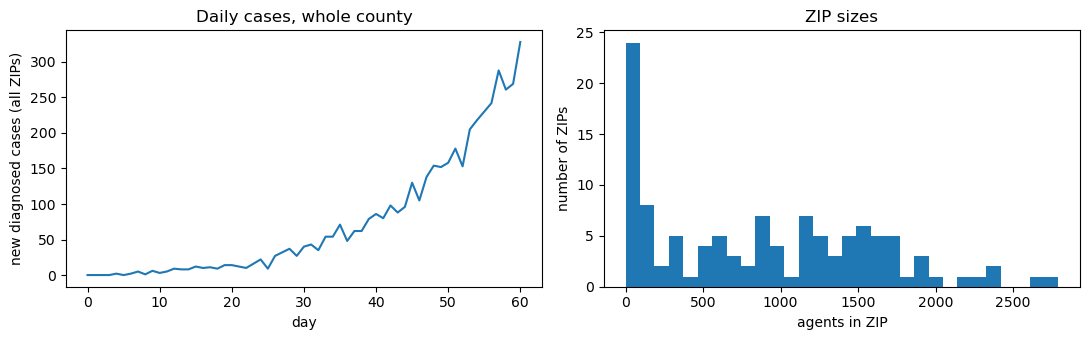

In [40]:
import matplotlib.pyplot as plt

# N[i] = number of simulated agents living in ZIP i (the denominator for the rate)
N = np.bincount(agent_row, minlength=len(zips))

print("agents per ZIP: min", N.min(), " median", int(np.median(N)), " max", N.max())
print("ZIPs with fewer than 50 agents:", (N < 50).sum(), "of", len(N))
print("ZIPs with 0 cases all run:", (cases.sum(axis=1) == 0).sum())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(cases.sum(axis=0))
ax[0].set_xlabel("day"); ax[0].set_ylabel("new diagnosed cases (all ZIPs)")
ax[0].set_title("Daily cases, whole county")
ax[1].hist(N, bins=30)
ax[1].set_xlabel("agents in ZIP"); ax[1].set_ylabel("number of ZIPs")
ax[1].set_title("ZIP sizes")
plt.tight_layout(); plt.show()

### Longer epidemic

In [41]:
sim = cv.Sim(
    pop_size=100_000, pop_type='rank', pop_infected=50, n_days=120, n_imports=0, rand_seed=1,
    density_raster=str(SD_DATA / 'san_diego_county_ppp_2020.tif'),
    boundary_shapefile=str(SD_DATA / 'sandiego_zip_boundaries.geojson'),
    sewershed_file=str(SD_DATA / 'sandiego_sewersheds.geojson'),
    interventions=[cv.test_prob(symp_prob=0.2, start_day=0)],
    verbose=0,
)
sim.initialize()
sim.run()

/storage/hcraddock/GitHub/covasim4wastewater/covasim/population.py:67: RuntimeWarning: 
The boundary file has no "population" column, so regions are weighted by their area. Add a "population" column to weight by population (it is not needed when pop_type="rank" uses a density_raster).
  cvm.warn(


Sim(<no label>; 2020-03-01 to 2020-06-29; pop: 100000 rank; epi: 72884⚙, 378☠)

### Zips

In [42]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components

# 1. Keep ZIPs with at least 50 agents
keep = N >= 50
print(f"keeping {keep.sum()} of {len(N)} ZIPs; dropped ZIPs hold {1 - N[keep].sum()/N.sum():.1%} of agents")

# 2. Neighbours: two ZIPs are neighbours if their outlines touch (tiny buffer closes hairline gaps)
geoms = zips.geometry.buffer(1e-6)
sidx = geoms.sindex
adj = np.zeros((len(zips), len(zips)), dtype=bool)
for i, g in enumerate(geoms):
    for j in sidx.query(g, predicate="intersects"):
        if j != i:
            adj[i, j] = True
adj = adj | adj.T

# 3. The model needs ONE connected map: check how many separate pieces the kept ZIPs form
n_pieces, piece = connected_components(sp.csr_matrix(adj[np.ix_(keep, keep)]), directed=False)
print("separate connected pieces among kept ZIPs:", n_pieces)
print("ZIPs in each piece:", np.bincount(piece))
print("average neighbours per ZIP:", adj[np.ix_(keep, keep)].sum(1).mean().round(1))

keeping 93 of 113 ZIPs; dropped ZIPs hold 0.4% of agents


/tmp/ipykernel_1362417/3051833094.py:10: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  geoms = zips.geometry.buffer(1e-6)


separate connected pieces among kept ZIPs: 1
ZIPs in each piece: [93]
average neighbours per ZIP: 5.1


In [33]:
n_agents = sim['pop_size']
zips["region_code"] = zips["region_code"].astype(int)

# Expected agents per ZIP = the ZIP's share of the raster population, times the number of agents
zips["expected_agents"] = zips["raster_pop"] / zips["raster_pop"].sum() * n_agents

# Realized agents per ZIP, counted from the simulation
realized = pd.Series(sim.people.region).value_counts()
zips["agents"] = realized.reindex(zips["region_code"]).fillna(0).to_numpy()

# Poisson-style z-score: how many "typical random wiggles" apart are realized and expected?
zips["z"] = (zips["agents"] - zips["expected_agents"]) / np.sqrt(zips["expected_agents"].clip(lower=1))

print("correlation:", np.corrcoef(zips["agents"], zips["expected_agents"])[0, 1].round(4))
print("ZIPs with |z| > 4:", (zips["z"].abs() > 4).sum(), "of", len(zips))
zips.loc[zips["z"].abs() > 4, ["zip", "community", "raster_pop", "expected_agents", "agents", "z"]]

NameError: name 'sim' is not defined